<a href="https://colab.research.google.com/github/madhuraneeli2008/EDAV-PROJECT/blob/main/Metro_Rail_Passenger_Usage_Analysis_FIXED_All_Graphs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Metro Rail Passenger Usage Analysis (Official Monthly Ridership)

**Student:** Neeli Madhura  
**Roll Number:** 160125737113  
**Course:** Exploratory Data Analysis & Visualization (EDAV)

This notebook analyses **published monthly passenger ridership for Hyderabad Metro**. The figures are taken from the official L&T Metro Rail (Hyderabad) ridership page and compiled into a CSV for analysis. This is real published monthly ridership data—not synthetic or simulated passenger records.

**Important scope note:** The source provides monthly system-wide totals, not passenger counts by individual station or hour. Therefore, the analysis focuses on monthly trends, month-to-month changes, descriptive statistics, and visualisations. It does not infer station-level or hourly patterns.

**Official source:** https://ltmetro.com/ridership/  
**Attribution:** Contains ridership figures published by L&T Metro Rail (Hyderabad) Limited. Please verify the source page for updates before reusing the dataset.

> **Important:** In Google Colab, choose **Runtime → Run all** from the top. Do not run a graph cell by itself after a runtime reset. The notebook now includes a built-in copy of the 12-month dataset, so it can run even if the CSV has not been uploaded.

## 1. Import libraries

We use pandas for data handling, NumPy for numerical calculations, and Matplotlib/Seaborn for charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import calendar
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load the official CSV file

Upload `Hyderabad_Metro_Official_Monthly_Ridership_2024_2025.csv` to the same Colab session. If the file is not present, the cell asks you to upload it.

In [2]:
csv_file = "Hyderabad_Metro_Official_Monthly_Ridership_2024_2025.csv"

if Path(csv_file).exists():
    df = pd.read_csv(csv_file)
    print(f"Loaded dataset from {csv_file}")
else:
    # Built-in fallback ensures the notebook runs without a separate CSV upload.
    from io import StringIO
    csv_text = """Month,Monthly_Ridership,Source_URL
2024-07,14454276,https://ltmetro.com/ridership/
2024-08,14589269,https://ltmetro.com/ridership/
2024-09,13981633,https://ltmetro.com/ridership/
2024-10,13681668,https://ltmetro.com/ridership/
2024-11,13443612,https://ltmetro.com/ridership/
2024-12,13828393,https://ltmetro.com/ridership/
2025-01,13248209,https://ltmetro.com/ridership/
2025-02,12591821,https://ltmetro.com/ridership/
2025-03,12887394,https://ltmetro.com/ridership/
2025-04,12906361,https://ltmetro.com/ridership/
2025-05,12594615,https://ltmetro.com/ridership/
2025-06,12432773,https://ltmetro.com/ridership/
"""
    df = pd.read_csv(StringIO(csv_text))
    print("CSV not found; using the dataset embedded in this notebook.")

print("Dataset loaded successfully. Shape:", df.shape)
display(df.head())


CSV not found; using the dataset embedded in this notebook.
Dataset loaded successfully. Shape: (12, 3)


,Month,Monthly_Ridership,Source_URL
0,2024-07,14454276,https://ltmetro.com/ridership/
1,2024-08,14589269,https://ltmetro.com/ridership/
2,2024-09,13981633,https://ltmetro.com/ridership/
3,2024-10,13681668,https://ltmetro.com/ridership/
4,2024-11,13443612,https://ltmetro.com/ridership/


## 3. Understand the dataset

The dataset has one record per month. `Month` is the year-month identifier and `Monthly_Ridership` is the published total number of passenger trips for that month. `Source_URL` records the official source.

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data type"))
print("\nMissing values:")
display(df.isna().sum().to_frame("Missing count"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
display(df.describe(include="all"))


Dataset shape: (12, 3)

Column names: ['Month', 'Monthly_Ridership', 'Source_URL']

Data types:


,Data type
Month,object
Monthly_Ridership,int64
Source_URL,object



Missing values:


,Missing count
Month,0
Monthly_Ridership,0
Source_URL,0



Duplicate rows: 0

Summary statistics:


,Month,Monthly_Ridership,Source_URL
count,12,1.200000e+01,12
unique,12,NaN,1
top,2024-07,NaN,https://ltmetro.com/ridership/
freq,1,NaN,12
mean,NaN,1.338667e+07,NaN
std,NaN,7.319708e+05,NaN
min,NaN,1.243277e+07,NaN
25%,NaN,1.281420e+07,NaN
50%,NaN,1.334591e+07,NaN
75%,NaN,1.386670e+07,NaN


## 4. Clean and prepare the data

Convert the month field to a date, convert ridership to a numeric type, sort chronologically, and check whether any month appears more than once. The source values are preserved; this section does not create or estimate passenger counts.

In [4]:
df["Month"] = pd.to_datetime(df["Month"], format="%Y-%m", errors="coerce")
df["Monthly_Ridership"] = pd.to_numeric(df["Monthly_Ridership"], errors="coerce")
df = df.dropna(subset=["Month", "Monthly_Ridership"]).copy()
df = df.sort_values("Month").reset_index(drop=True)
df["Year"] = df["Month"].dt.year
df["Month_Name"] = df["Month"].dt.strftime("%B")
df["Days_In_Month"] = df["Month"].dt.days_in_month
df["Average_Daily_Ridership"] = df["Monthly_Ridership"] / df["Days_In_Month"]
df["MoM_Change"] = df["Monthly_Ridership"].diff()
df["MoM_Change_Percent"] = df["Monthly_Ridership"].pct_change() * 100

print("Prepared dataset:")
display(df.head())


Prepared dataset:


,Month,Monthly_Ridership,Source_URL,Year,Month_Name,Days_In_Month,Average_Daily_Ridership,MoM_Change,MoM_Change_Percent
0,2024-07-01,14454276,https://ltmetro.com/ridership/,2024,July,31,466266.967742,NaN,NaN
1,2024-08-01,14589269,https://ltmetro.com/ridership/,2024,August,31,470621.580645,134993.0,0.933931
2,2024-09-01,13981633,https://ltmetro.com/ridership/,2024,September,30,466054.433333,-607636.0,-4.164952
3,2024-10-01,13681668,https://ltmetro.com/ridership/,2024,October,31,441344.129032,-299965.0,-2.145422
4,2024-11-01,13443612,https://ltmetro.com/ridership/,2024,November,30,448120.400000,-238056.0,-1.739963


## 5. Data quality checks

The checks below confirm date coverage, duplicate months, and whether any ridership values are missing or non-positive.

In [5]:
print("Date range:", df["Month"].min().strftime("%B %Y"), "to", df["Month"].max().strftime("%B %Y"))
print("Number of monthly records:", len(df))
print("Unique months:", df["Month"].nunique())
print("Duplicate months:", df["Month"].duplicated().sum())
print("Missing ridership values:", df["Monthly_Ridership"].isna().sum())
print("Non-positive ridership values:", (df["Monthly_Ridership"] <= 0).sum())


Date range: July 2024 to June 2025
Number of monthly records: 12
Unique months: 12
Duplicate months: 0
Missing ridership values: 0
Non-positive ridership values: 0


## 6. Key descriptive statistics

These metrics describe the 12 published monthly totals in this file. They are descriptive summaries of the selected period, not a forecast of future ridership.

In [6]:
stats = pd.Series({
    "Months analysed": len(df),
    "Total passenger trips across period": int(df["Monthly_Ridership"].sum()),
    "Average monthly ridership": df["Monthly_Ridership"].mean(),
    "Median monthly ridership": df["Monthly_Ridership"].median(),
    "Minimum monthly ridership": df["Monthly_Ridership"].min(),
    "Maximum monthly ridership": df["Monthly_Ridership"].max(),
    "Standard deviation": df["Monthly_Ridership"].std(),
})
display(stats.to_frame("Value"))


,Value
Months analysed,1.200000e+01
Total passenger trips across period,1.606400e+08
Average monthly ridership,1.338667e+07
Median monthly ridership,1.334591e+07
Minimum monthly ridership,1.243277e+07
Maximum monthly ridership,1.458927e+07
Standard deviation,7.319708e+05


## 7. Monthly passenger ridership trend

The line chart shows how the published system-wide monthly total changes across the period.

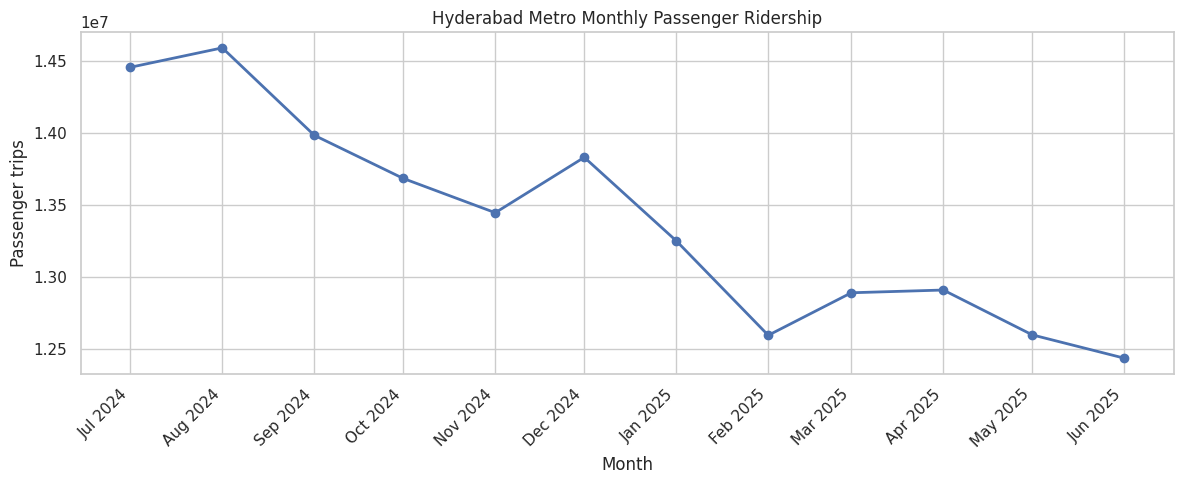

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(df["Month"], df["Monthly_Ridership"], marker="o", linewidth=2)
plt.title("Hyderabad Metro Monthly Passenger Ridership")
plt.xlabel("Month")
plt.ylabel("Passenger trips")
plt.xticks(df["Month"], df["Month"].dt.strftime("%b %Y"), rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 8. Ridership by month (bar chart)

This chart makes comparisons between consecutive months easier. The x-axis follows chronological order.

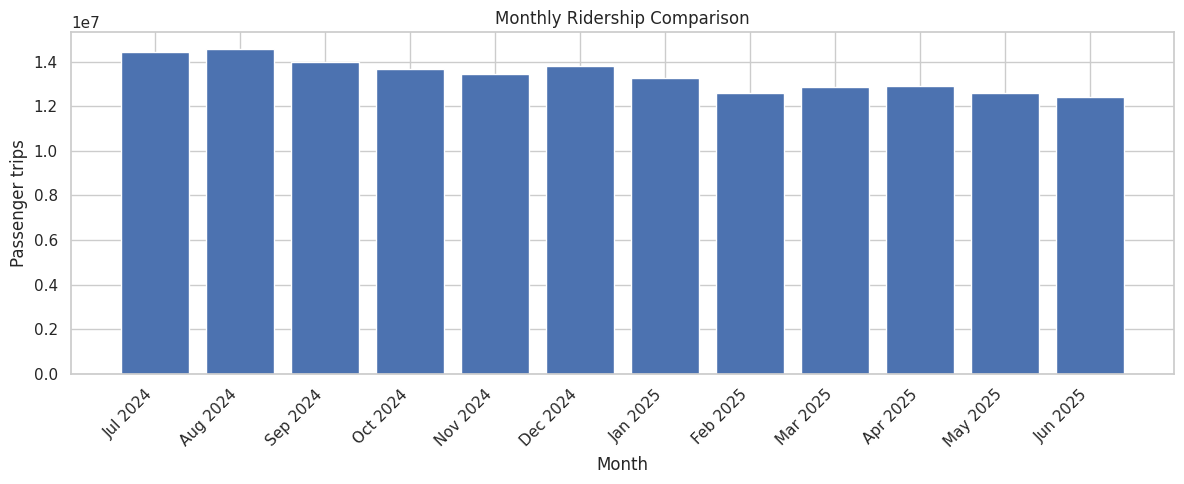

In [8]:
plt.figure(figsize=(12, 5))
plt.bar(df["Month"].dt.strftime("%b %Y"), df["Monthly_Ridership"])
plt.title("Monthly Ridership Comparison")
plt.xlabel("Month")
plt.ylabel("Passenger trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 9. Month-to-month change

Absolute change is the current month total minus the previous month total. Percentage change divides that difference by the previous month's total. The first month has no previous month in this dataset, so its change is undefined.

,Month,Monthly_Ridership,MoM_Change,MoM_Change_Percent
0,July 2024,14454276,NaN,NaN
1,August 2024,14589269,134993.0,0.93
2,September 2024,13981633,-607636.0,-4.16
3,October 2024,13681668,-299965.0,-2.15
4,November 2024,13443612,-238056.0,-1.74
5,December 2024,13828393,384781.0,2.86
6,January 2025,13248209,-580184.0,-4.20
7,February 2025,12591821,-656388.0,-4.95
8,March 2025,12887394,295573.0,2.35
9,April 2025,12906361,18967.0,0.15


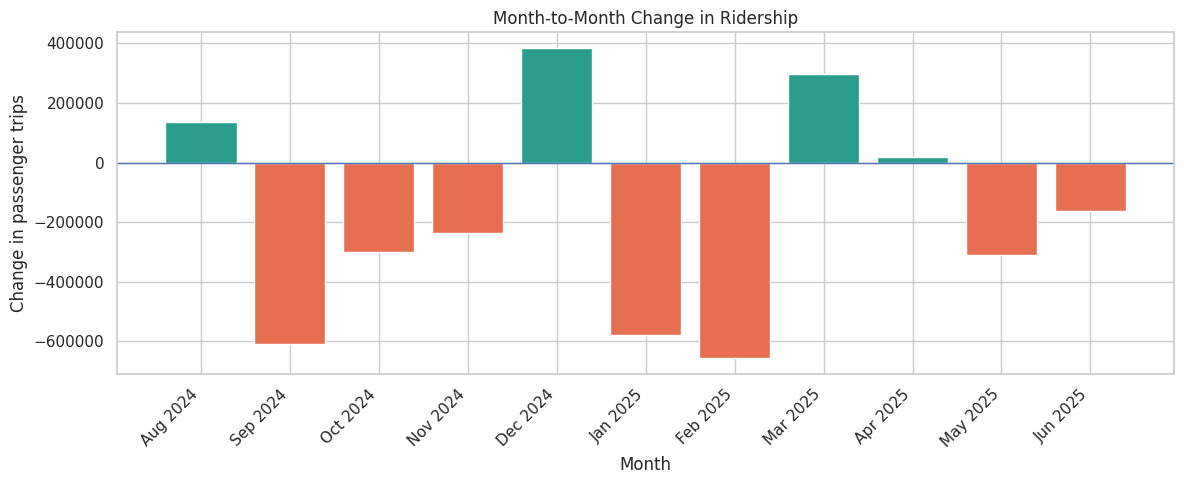

In [9]:
display(df[["Month", "Monthly_Ridership", "MoM_Change", "MoM_Change_Percent"]].assign(
    Month=lambda x: x["Month"].dt.strftime("%B %Y"),
    MoM_Change_Percent=lambda x: x["MoM_Change_Percent"].round(2)
))

plt.figure(figsize=(12, 5))
colors = ["#2a9d8f" if x >= 0 else "#e76f51" for x in df["MoM_Change"].fillna(0)]
plt.bar(df["Month"].dt.strftime("%b %Y"), df["MoM_Change"], color=colors)
plt.axhline(0, linewidth=1)
plt.title("Month-to-Month Change in Ridership")
plt.xlabel("Month")
plt.ylabel("Change in passenger trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 10. Estimated average daily ridership

Monthly totals are divided by the number of calendar days in each month. This is a calculated average per calendar day, not an official daily ridership series; it does not show differences between weekdays, weekends, or individual dates.

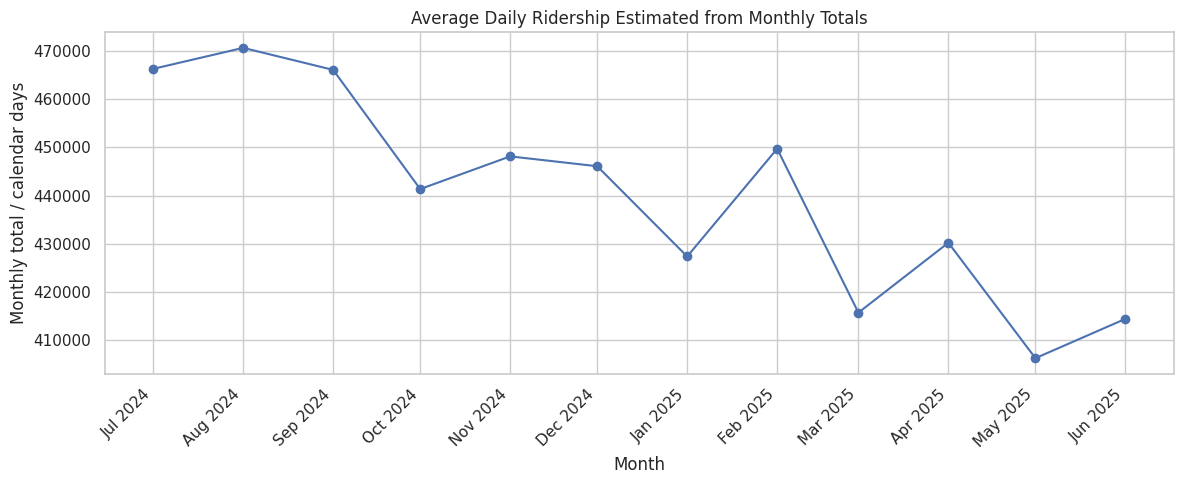

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(df["Month"], df["Average_Daily_Ridership"], marker="o")
plt.title("Average Daily Ridership Estimated from Monthly Totals")
plt.xlabel("Month")
plt.ylabel("Monthly total / calendar days")
plt.xticks(df["Month"], df["Month"].dt.strftime("%b %Y"), rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 11. Identify the highest and lowest months

The following code identifies the maximum and minimum monthly totals in the available period. These are period-specific comparisons, not all-time records.

In [11]:
highest = df.loc[df["Monthly_Ridership"].idxmax()]
lowest = df.loc[df["Monthly_Ridership"].idxmin()]
print(f"Highest month: {highest['Month'].strftime('%B %Y')} — {highest['Monthly_Ridership']:,.0f} passenger trips")
print(f"Lowest month:  {lowest['Month'].strftime('%B %Y')} — {lowest['Monthly_Ridership']:,.0f} passenger trips")
print(f"Difference:    {highest['Monthly_Ridership'] - lowest['Monthly_Ridership']:,.0f} passenger trips")


Highest month: August 2024 — 14,589,269 passenger trips
Lowest month:  June 2025 — 12,432,773 passenger trips
Difference:    2,156,496 passenger trips


## 12. Year-level summary

Because the selected source period crosses two calendar years, the yearly summary groups the available months by year. The 2024 and 2025 totals here are partial-year totals for the months present in the CSV, not full calendar-year totals.

In [12]:
year_summary = df.groupby("Year").agg(
    Months_Represented=("Month", "count"),
    Total_Ridership_For_Available_Months=("Monthly_Ridership", "sum"),
    Average_Monthly_Ridership=("Monthly_Ridership", "mean"),
    Lowest_Month=("Monthly_Ridership", "min"),
    Highest_Month=("Monthly_Ridership", "max")
).round(2)
display(year_summary)


,Months_Represented,Total_Ridership_For_Available_Months,Average_Monthly_Ridership,Lowest_Month,Highest_Month
Year,,,,,
2024,6,83978851,13996475.17,13443612,14589269
2025,6,76661173,12776862.17,12432773,13248209


## 13. Correlation and interpretation caution

There is only one main numeric observed measure—monthly ridership—plus date-derived fields. A correlation matrix across these variables would not establish causal relationships. This project therefore prioritises time-trend comparisons and descriptive summaries instead of unsupported causal claims.

In [13]:
print("Monthly ridership range:", f"{df['Monthly_Ridership'].min():,.0f}", "to", f"{df['Monthly_Ridership'].max():,.0f}")
print("Average monthly ridership:", f"{df['Monthly_Ridership'].mean():,.0f}")
print("Median monthly ridership:", f"{df['Monthly_Ridership'].median():,.0f}")


Monthly ridership range: 12,432,773 to 14,589,269
Average monthly ridership: 13,386,669
Median monthly ridership: 13,345,910


## 14. Findings generated from the data

This cell creates a short, data-driven summary so that the findings stay tied to the loaded CSV. Read these results together with the plots and the source period.

In [14]:
change = df["Monthly_Ridership"].iloc[-1] - df["Monthly_Ridership"].iloc[0]
change_pct = (change / df["Monthly_Ridership"].iloc[0]) * 100
print(f"• Analysed {len(df)} monthly records from {df['Month'].min():%B %Y} to {df['Month'].max():%B %Y}.")
print(f"• Average monthly ridership in this period: {df['Monthly_Ridership'].mean():,.0f} passenger trips.")
print(f"• Highest month in this file: {highest['Month']:%B %Y} ({highest['Monthly_Ridership']:,.0f}).")
print(f"• Lowest month in this file: {lowest['Month']:%B %Y} ({lowest['Monthly_Ridership']:,.0f}).")
print(f"• Change from the first to the last month in this file: {change:,.0f} trips ({change_pct:.2f}%).")
print("• These findings describe the published monthly totals only; they do not identify station-level or hourly passenger behaviour.")


• Analysed 12 monthly records from July 2024 to June 2025.
• Average monthly ridership in this period: 13,386,669 passenger trips.
• Highest month in this file: August 2024 (14,589,269).
• Lowest month in this file: June 2025 (12,432,773).
• Change from the first to the last month in this file: -2,021,503 trips (-13.99%).
• These findings describe the published monthly totals only; they do not identify station-level or hourly passenger behaviour.


## 15. Conclusion, limitations, and future scope

### Conclusion
The project demonstrates how official monthly metro ridership statistics can be loaded from CSV, checked for basic data-quality issues, summarised with descriptive statistics, and visualised using time-series and comparison charts. Month-to-month changes help identify periods of increase or decrease within the selected data window.

### Limitations
- The source page provides monthly system-wide ridership totals for the listed months only.
- The dataset does not include station-wise, hour-wise, trip-purpose, fare-category, or passenger demographic details.
- Average daily ridership is calculated by dividing the monthly total by calendar days; it is not a published daily count.
- The period in this CSV is July 2024 through June 2025, so results should not be described as current or all-time statistics.

### Future scope
If the operator publishes daily or station-wise passenger counts, the project can be expanded to weekday/weekend analysis, peak-hour analysis, station comparisons, seasonal analysis, and forecasting with proper validation.

## 16. References and data attribution

1. L&T Metro Rail (Hyderabad) Limited, **Ridership**: https://ltmetro.com/ridership/ (monthly ridership figures for July 2024–June 2025).
2. Hyderabad Metro Rail Limited, **Open Data**: https://hmrl.co.in/open-data/ (official static GTFS data covers routes, stops, schedules and fares; it does not provide the monthly passenger totals used in this notebook).
3. pandas documentation: https://pandas.pydata.org/docs/
4. Matplotlib documentation: https://matplotlib.org/stable/
5. Seaborn documentation: https://seaborn.pydata.org/

**Data note:** The supplied CSV is a CSV-format compilation of figures published in the official L&T Metro ridership table; it is not represented as an original downloadable CSV released by L&T Metro. Source attribution is retained in every row.

## 16. Additional visualizations with Matplotlib and Seaborn

The following plots extend the analysis using the same monthly ridership dataset. Since the dataset contains monthly system-wide totals rather than station-level or hourly observations, plots that compare categories use the available `Year` and `Month_Name` fields. Interpret these visualizations as summaries of the records in this file, not as station-level or passenger-level behaviour.



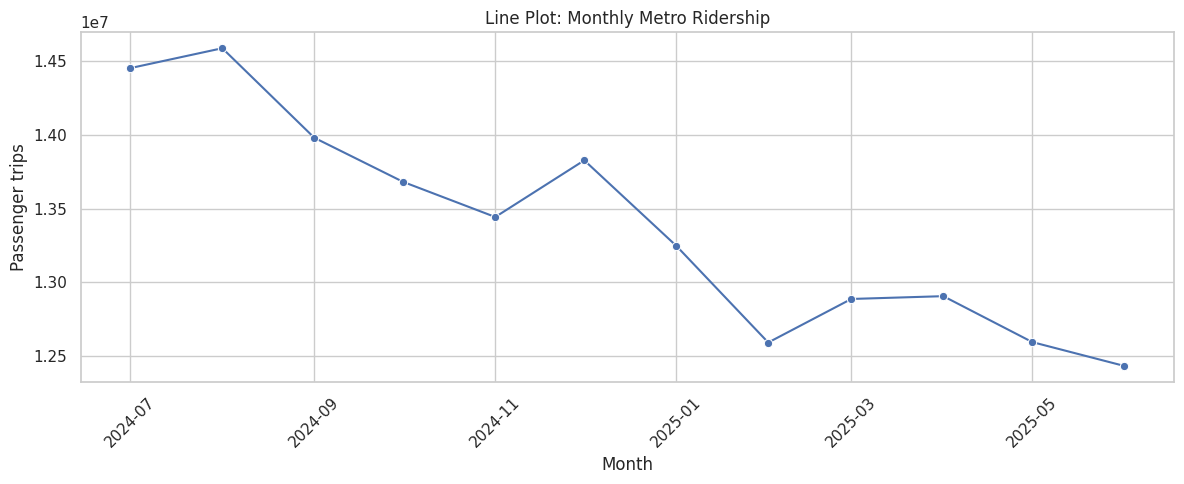

In [15]:
# 1. Line plot: monthly ridership trend
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x="Month", y="Monthly_Ridership", marker="o")
plt.title("Line Plot: Monthly Metro Ridership")
plt.xlabel("Month")
plt.ylabel("Passenger trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


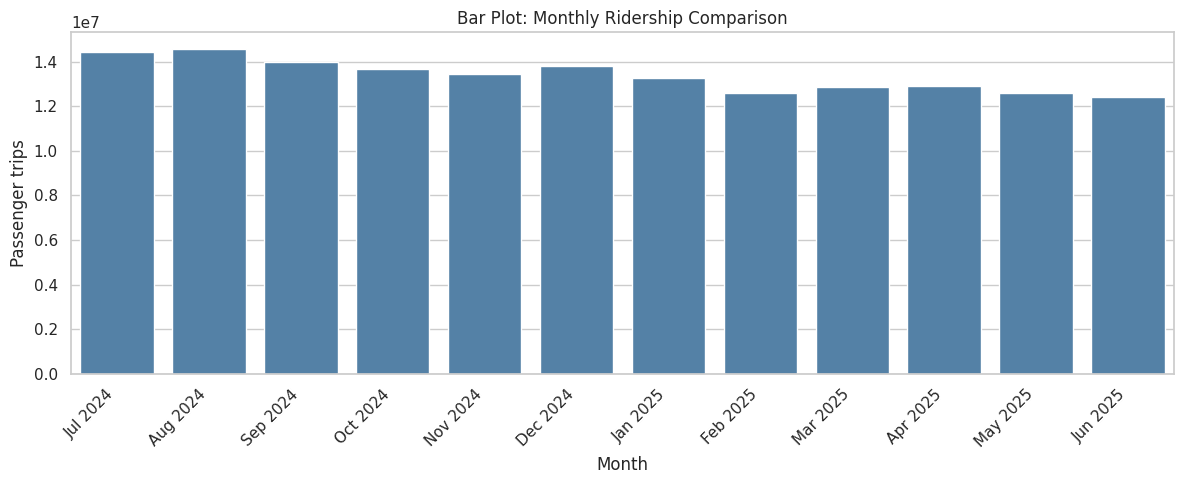

In [16]:
# 2. Bar plot: compare ridership by month
plt.figure(figsize=(12, 5))
sns.barplot(data=df, x=df["Month"].dt.strftime("%b %Y"), y="Monthly_Ridership", color="steelblue")
plt.title("Bar Plot: Monthly Ridership Comparison")
plt.xlabel("Month")
plt.ylabel("Passenger trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


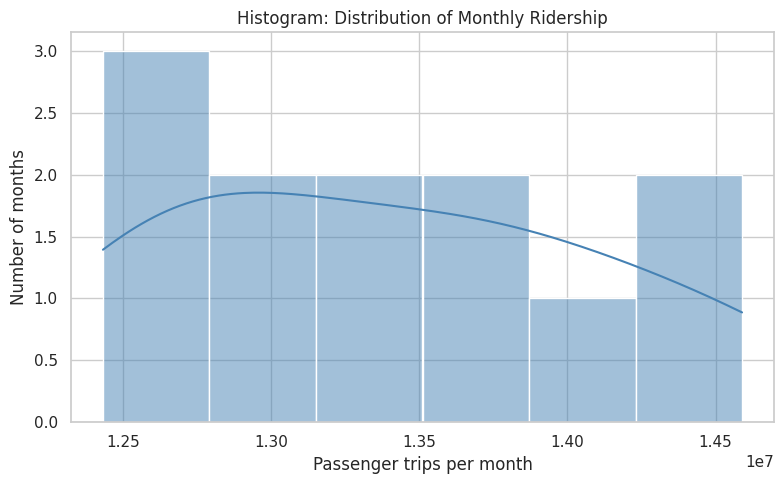

In [17]:
# 3. Histogram: distribution of monthly ridership
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Monthly_Ridership", bins=min(8, max(3, len(df)//2)), kde=True, color="steelblue")
plt.title("Histogram: Distribution of Monthly Ridership")
plt.xlabel("Passenger trips per month")
plt.ylabel("Number of months")
plt.tight_layout()
plt.show()


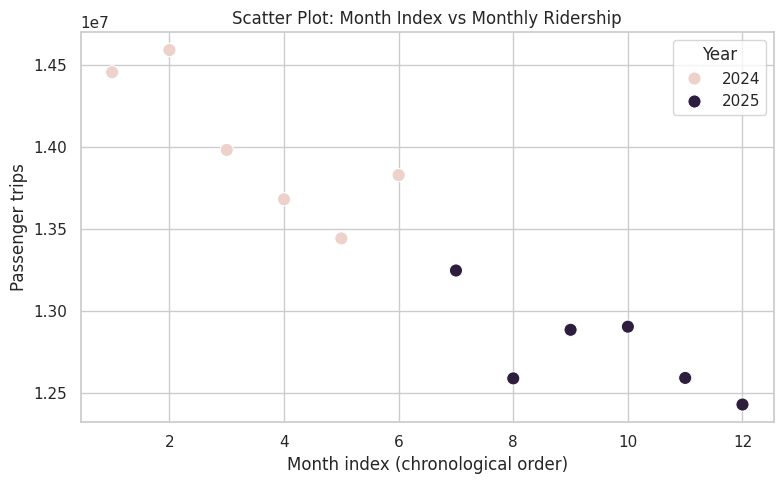

In [18]:
# 4. Scatter plot: month index versus ridership
scatter_df = df.copy()
scatter_df["Month_Index"] = np.arange(1, len(scatter_df) + 1)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=scatter_df, x="Month_Index", y="Monthly_Ridership", hue="Year", s=90)
plt.title("Scatter Plot: Month Index vs Monthly Ridership")
plt.xlabel("Month index (chronological order)")
plt.ylabel("Passenger trips")
plt.tight_layout()
plt.show()


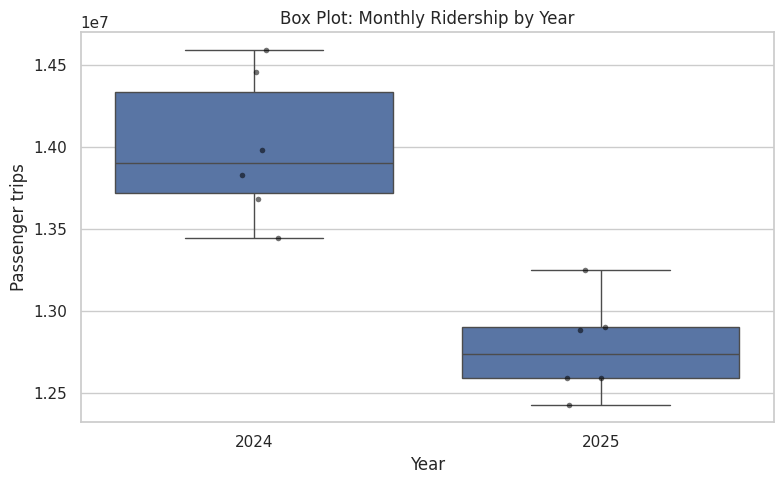

In [19]:
# 5. Box plot: ridership distribution by year
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Year", y="Monthly_Ridership")
sns.stripplot(data=df, x="Year", y="Monthly_Ridership", color="black", alpha=0.55, size=4)
plt.title("Box Plot: Monthly Ridership by Year")
plt.xlabel("Year")
plt.ylabel("Passenger trips")
plt.tight_layout()
plt.show()


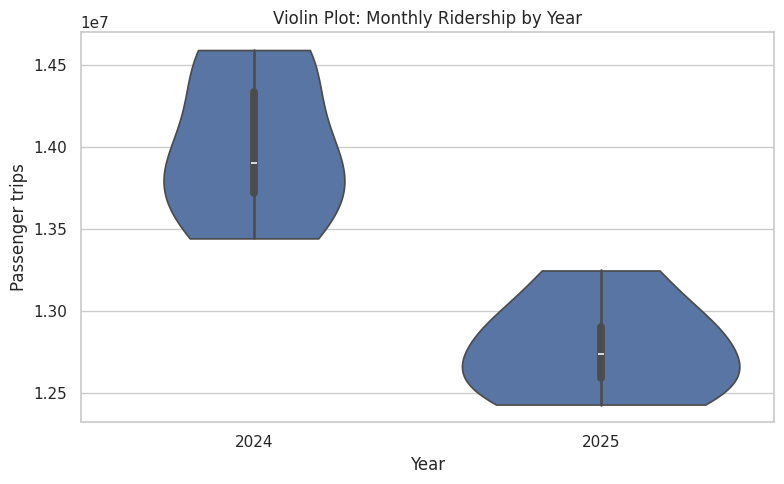

In [20]:
# 6. Violin plot: distribution by year (descriptive only for small samples)
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="Year", y="Monthly_Ridership", inner="box", cut=0)
plt.title("Violin Plot: Monthly Ridership by Year")
plt.xlabel("Year")
plt.ylabel("Passenger trips")
plt.tight_layout()
plt.show()


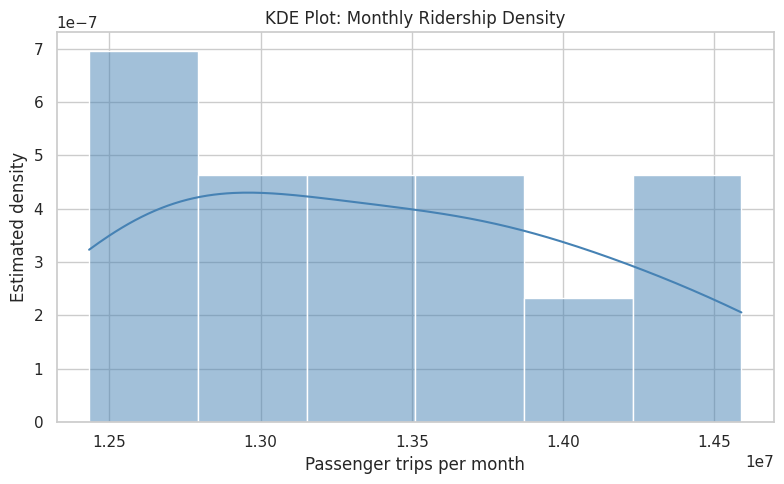

In [21]:
# 7. KDE plot: smoothed distribution of monthly ridership
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Monthly_Ridership", stat="density", kde=(df["Monthly_Ridership"].nunique() > 1), bins=min(8, max(3, len(df)//2)), color="steelblue")
plt.title("KDE Plot: Monthly Ridership Density")
plt.xlabel("Passenger trips per month")
plt.ylabel("Estimated density")
plt.tight_layout()
plt.show()


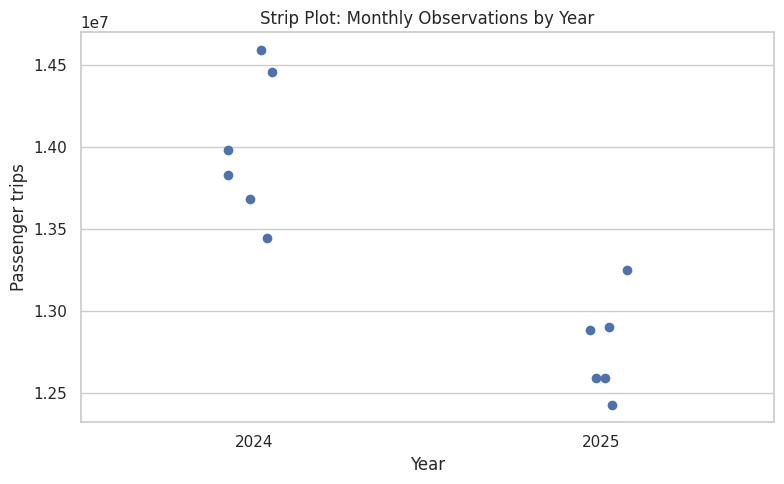

In [22]:
# 8. Strip plot: show each monthly observation by year
plt.figure(figsize=(8, 5))
sns.stripplot(data=df, x="Year", y="Monthly_Ridership", jitter=True, size=7)
plt.title("Strip Plot: Monthly Observations by Year")
plt.xlabel("Year")
plt.ylabel("Passenger trips")
plt.tight_layout()
plt.show()


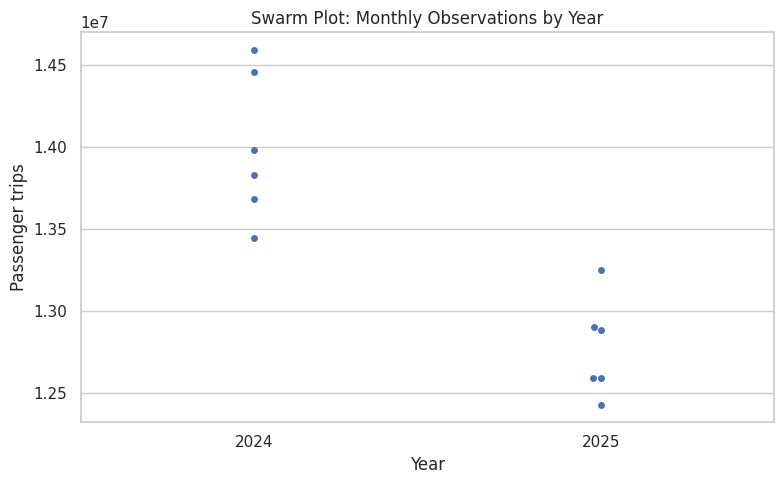

In [23]:
# 9. Swarm plot: show individual observations with reduced overlap
plt.figure(figsize=(8, 5))
try:
    sns.swarmplot(data=df, x="Year", y="Monthly_Ridership", size=5)
    plt.title("Swarm Plot: Monthly Observations by Year")
    plt.xlabel("Year")
    plt.ylabel("Passenger trips")
    plt.tight_layout()
    plt.show()
except Exception as e:
    plt.close()
    print("Swarm plot could not be drawn for this dataset:", e)


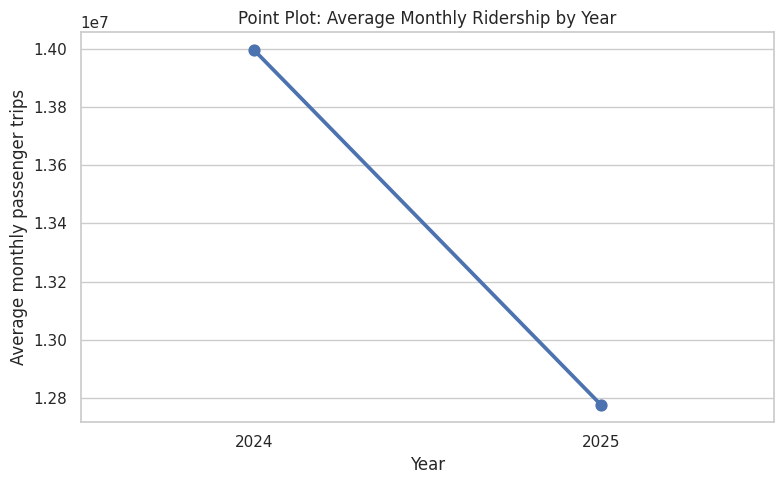

In [24]:
# 10. Point plot: yearly mean monthly ridership with uncertainty interval
plt.figure(figsize=(8, 5))
sns.pointplot(data=df, x="Year", y="Monthly_Ridership", ci=None)
plt.title("Point Plot: Average Monthly Ridership by Year")
plt.xlabel("Year")
plt.ylabel("Average monthly passenger trips")
plt.tight_layout()
plt.show()


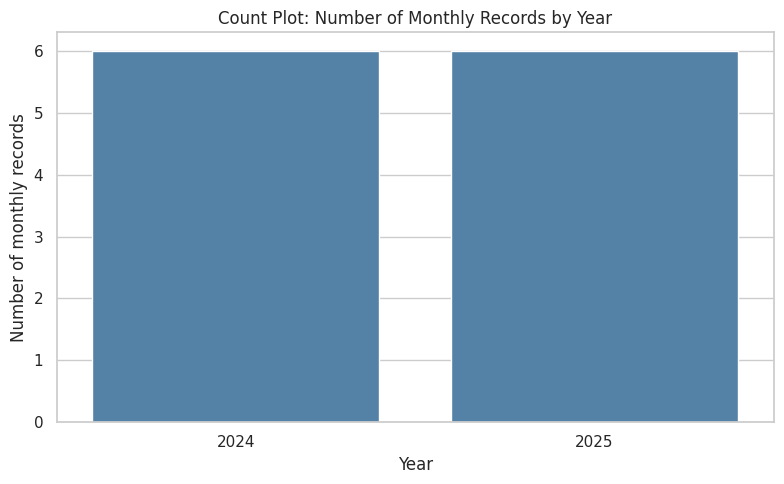

In [25]:
# 11. Count plot: number of monthly records available per year
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Year", color="steelblue")
plt.title("Count Plot: Number of Monthly Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of monthly records")
plt.tight_layout()
plt.show()


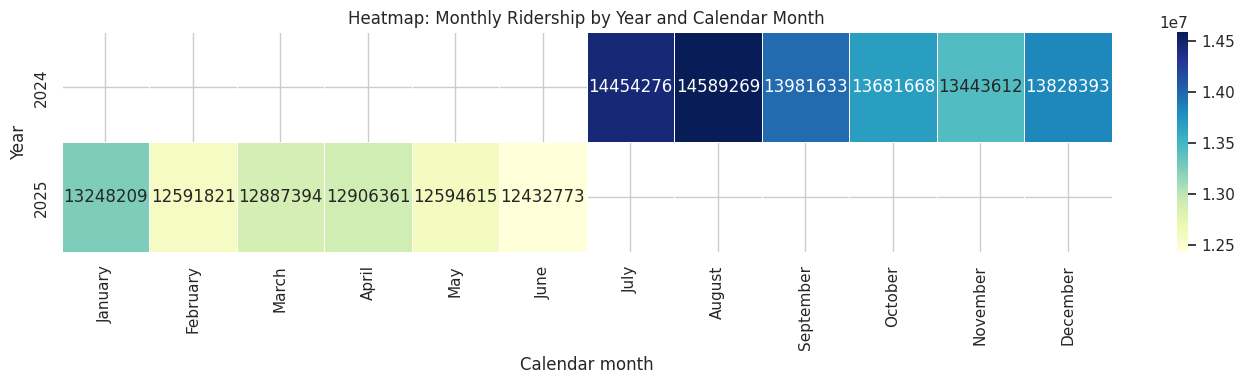

In [26]:
# 12. Heatmap: monthly ridership by year and calendar month
month_order = list(calendar.month_name)[1:]
heat_df = df.copy()
heat_df["Month_Name"] = heat_df["Month"].dt.month_name()
ridership_pivot = heat_df.pivot_table(
    index="Year", columns="Month_Name", values="Monthly_Ridership", aggfunc="mean"
).reindex(columns=month_order)
plt.figure(figsize=(14, 4))
sns.heatmap(ridership_pivot, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5)
plt.title("Heatmap: Monthly Ridership by Year and Calendar Month")
plt.xlabel("Calendar month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


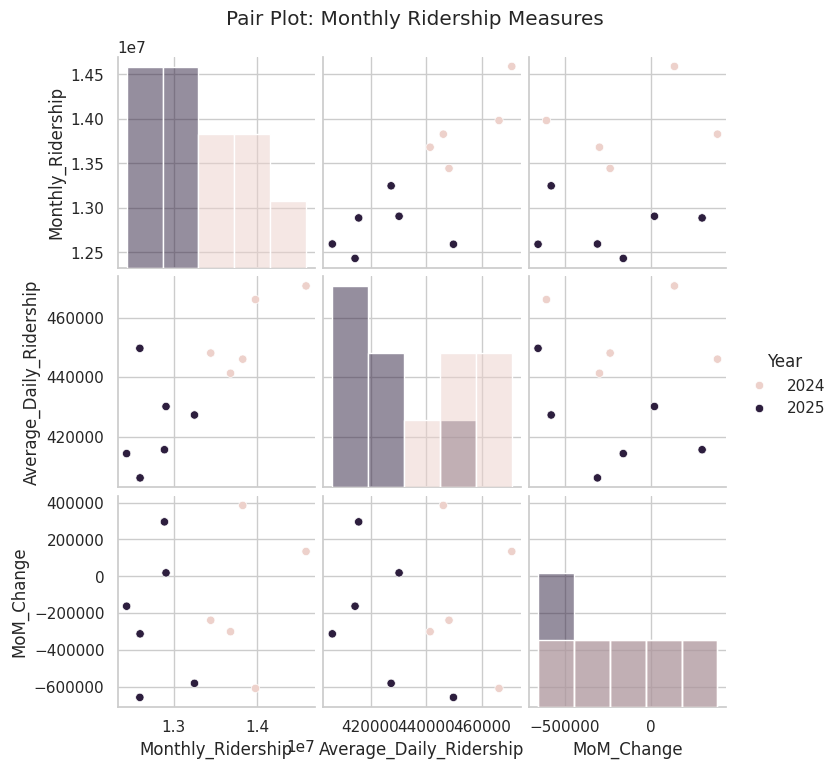

In [27]:
# 13. Pair plot: relationships among available numeric measures
# These variables are derived from the same monthly series, so relationships are descriptive, not causal.
pair_df = df[["Monthly_Ridership", "Average_Daily_Ridership", "MoM_Change", "Year"]].copy()
pair_df = pair_df.replace([np.inf, -np.inf], np.nan).dropna()
if len(pair_df) >= 3:
    sns.pairplot(pair_df, vars=["Monthly_Ridership", "Average_Daily_Ridership", "MoM_Change"], hue="Year", diag_kind="hist")
    plt.suptitle("Pair Plot: Monthly Ridership Measures", y=1.02)
    plt.show()
else:
    print("Pair plot needs at least three complete rows; not enough data is available.")


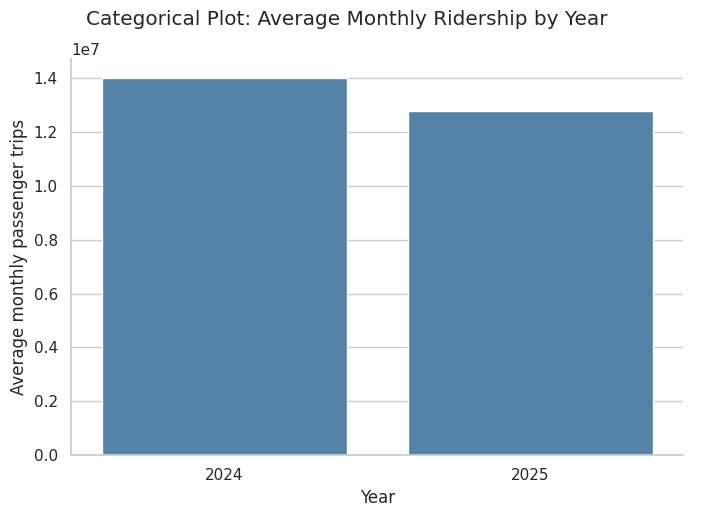

In [28]:
# 14. Categorical plot: compare monthly ridership across years
g = sns.catplot(data=df, x="Year", y="Monthly_Ridership", kind="bar", ci=None, color="steelblue", height=5, aspect=1.4)
g.set_axis_labels("Year", "Average monthly passenger trips")
g.fig.suptitle("Categorical Plot: Average Monthly Ridership by Year", y=1.03)
plt.show()


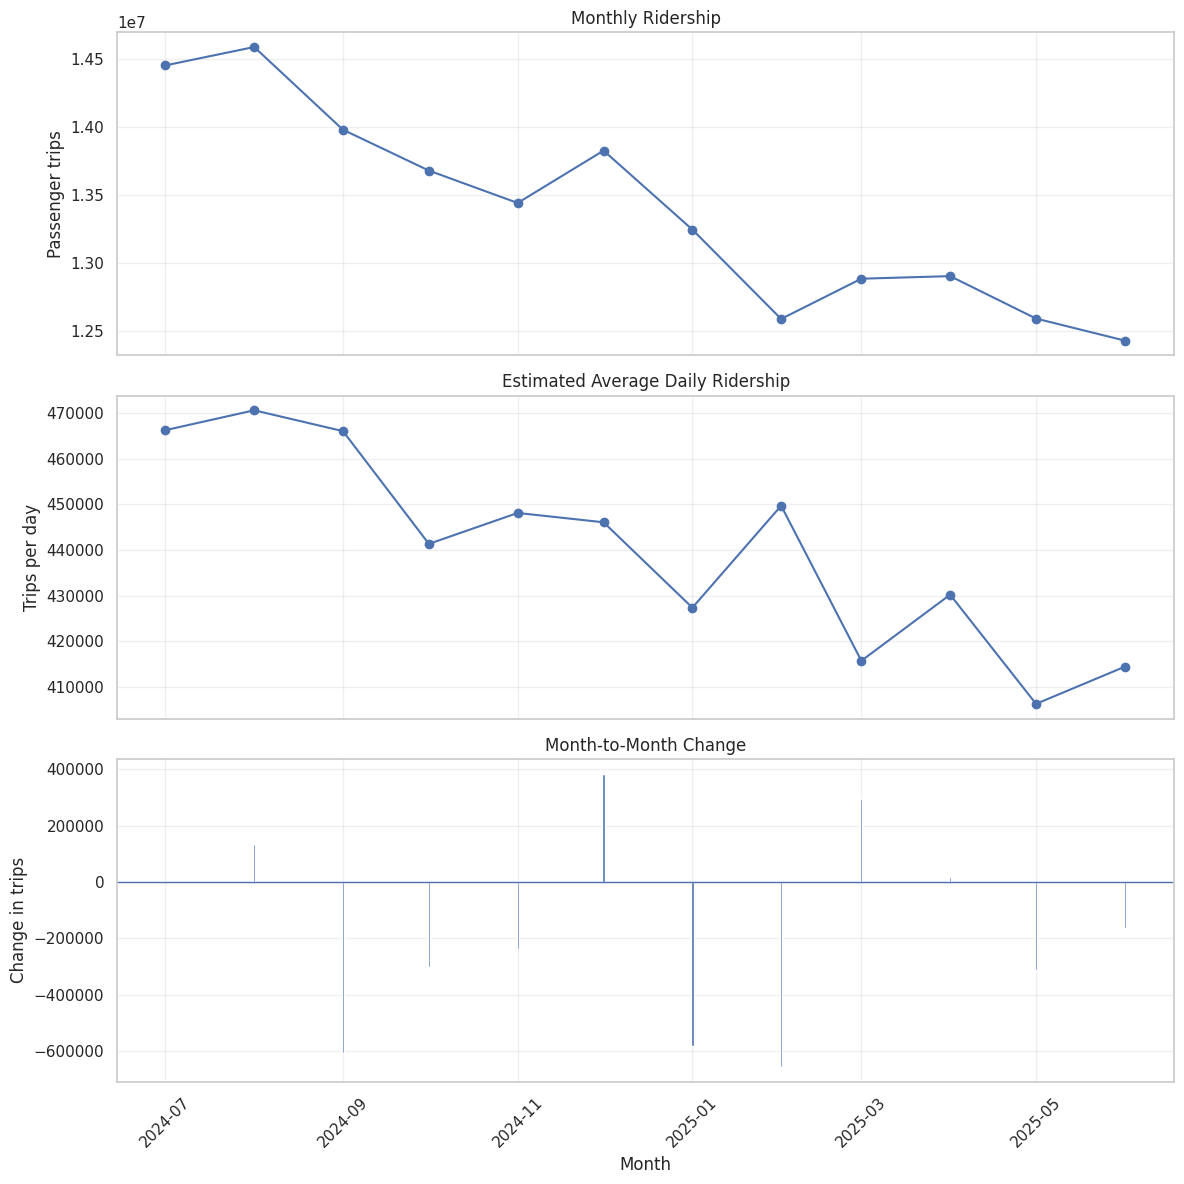

In [29]:
# 15. Subplots: view monthly totals, daily average, and month-to-month change together
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
axes[0].plot(df["Month"], df["Monthly_Ridership"], marker="o")
axes[0].set_title("Monthly Ridership")
axes[0].set_ylabel("Passenger trips")

axes[1].plot(df["Month"], df["Average_Daily_Ridership"], marker="o")
axes[1].set_title("Estimated Average Daily Ridership")
axes[1].set_ylabel("Trips per day")

axes[2].bar(df["Month"], df["MoM_Change"])
axes[2].axhline(0, linewidth=1)
axes[2].set_title("Month-to-Month Change")
axes[2].set_ylabel("Change in trips")
axes[2].set_xlabel("Month")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


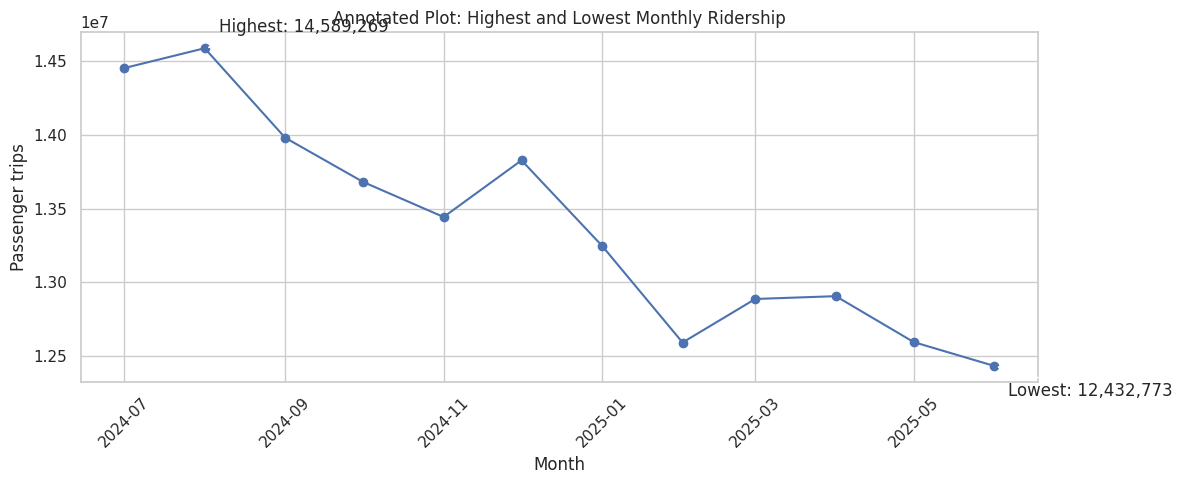

In [30]:
# 16. Annotated plot: label the highest and lowest monthly ridership
highest_row = df.loc[df["Monthly_Ridership"].idxmax()]
lowest_row = df.loc[df["Monthly_Ridership"].idxmin()]
plt.figure(figsize=(12, 5))
plt.plot(df["Month"], df["Monthly_Ridership"], marker="o")
plt.annotate(
    f"Highest: {highest_row['Monthly_Ridership']:,.0f}",
    xy=(highest_row["Month"], highest_row["Monthly_Ridership"]),
    xytext=(10, 12), textcoords="offset points", arrowprops={"arrowstyle": "->"}
)
plt.annotate(
    f"Lowest: {lowest_row['Monthly_Ridership']:,.0f}",
    xy=(lowest_row["Month"], lowest_row["Monthly_Ridership"]),
    xytext=(10, -22), textcoords="offset points", arrowprops={"arrowstyle": "->"}
)
plt.title("Annotated Plot: Highest and Lowest Monthly Ridership")
plt.xlabel("Month")
plt.ylabel("Passenger trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Notes on interpretation

- A histogram and KDE plot show the distribution of the recorded monthly totals.
- Box, violin, strip, and swarm plots group observations by year. If there are very few records in a year, distribution shapes may be unstable.
- The count plot shows how many monthly records are present for each year; it does not show passenger counts.
- The heatmap only displays months present in the dataset; blank cells mean no record was available for that year-month.
- Pair plots use measures derived from the same ridership series. They should not be interpreted as evidence of causation.
- A station-level or hourly heatmap cannot be created from this file unless station-level or hourly data is added.


## 17. Appendix: Save the prepared dataset

This optional cell saves the cleaned and enriched analysis table to a new CSV file.

In [31]:
output_file = "Hyderabad_Metro_Ridership_Cleaned_Analysis.csv"
df.to_csv(output_file, index=False)
print("Saved:", output_file)
try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("The output file is in the current working directory.")


Saved: Hyderabad_Metro_Ridership_Cleaned_Analysis.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>